In [1]:
import os
import cv2
import numpy as np 
import matplotlib.pyplot as plt
from opencv_tools import opencv_tools

### Crop Image

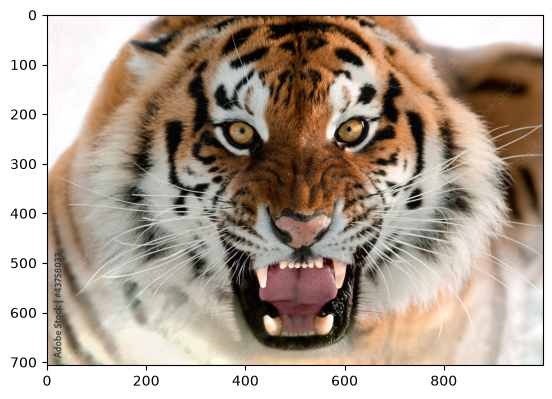

In [2]:
img = cv2.imread('../dataset/img/tiger.jpg')
img = cv2.cvtColor(src=img, code=cv2.COLOR_BGR2RGB)
plt.imshow(img)

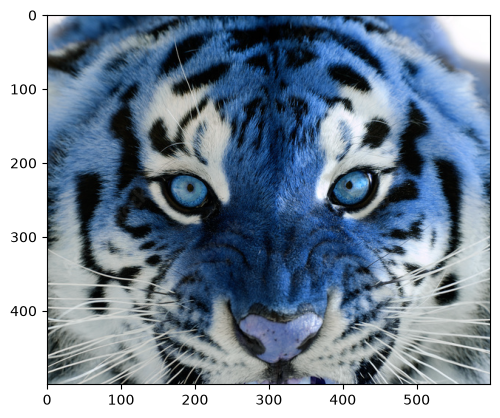

In [8]:
cropped_img = img[0:500, 200:800]
opencv_tools.show_img_by_matplotlib(cropped_img)

### Rotate Img

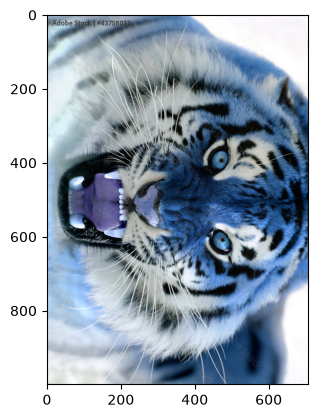

In [9]:
rotate_img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
opencv_tools.show_img_by_matplotlib(rotate_img)

### Resize Img

In [ ]:
w, h, c = img.shape

In [13]:
resized_img = cv2.resize(src=img, dsize=(w//2, h//2))
print(f"Original size = {img.shape}")
print(f"After resized = {resized_img.shape}")

Original size = (707, 1000, 3)
After resized = (500, 353, 3)


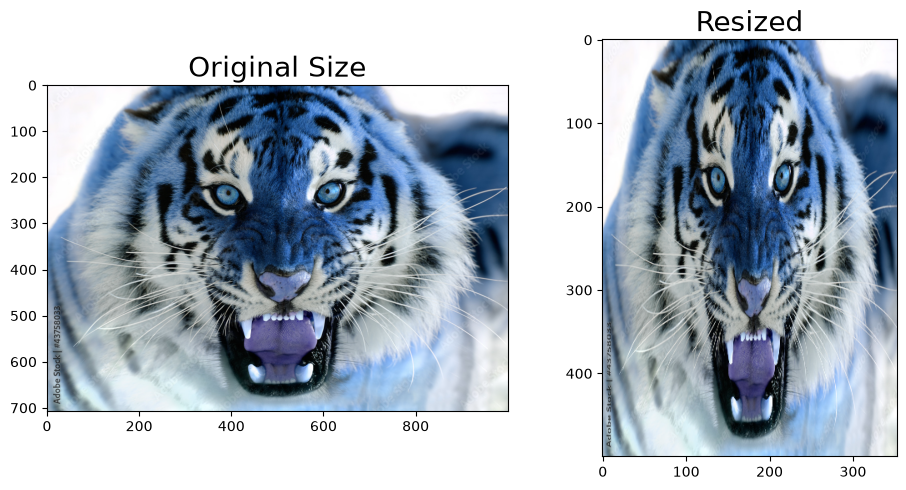

In [14]:
opencv_tools.show_img_by_matplotlib_1x2(
    "Original Size", img,
    "Resized", resized_img)

In [16]:
x_scaled = 1.5 #水平方向放小
y_scaled= 0.5 #垂直方向放大

scaled_img = cv2.resize(src=img, dsize=None, fx=x_scaled, fy=y_scaled)
print(f"Original size = {img.shape}")
print(f"After resized = {scaled_img.shape}")

Original size = (707, 1000, 3)
After resized = (354, 1500, 3)


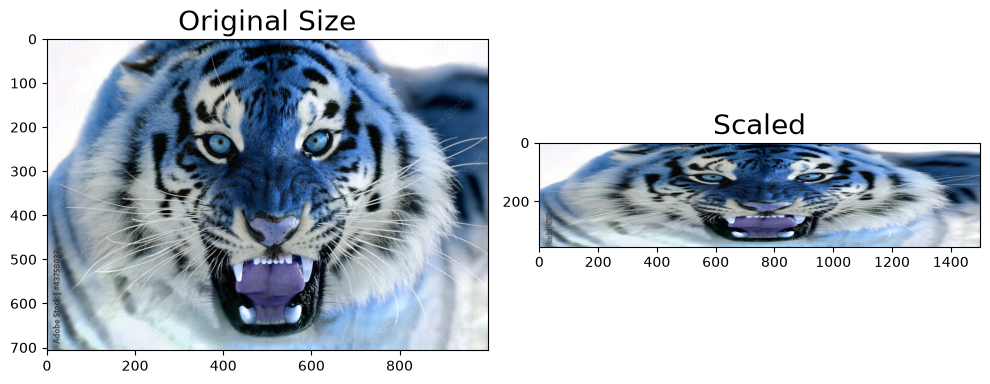

In [17]:
opencv_tools.show_img_by_matplotlib_1x2(
    "Original Size", img,
    "Scaled", scaled_img)

### Flip Image

In [ ]:
horizontal_flip = cv2.flip(src=img, flipCode=1) 
vertical_flip = cv2.flip(src=img, flipCode=0)
both_flip = cv2.flip(src=img, flipCode=-1)

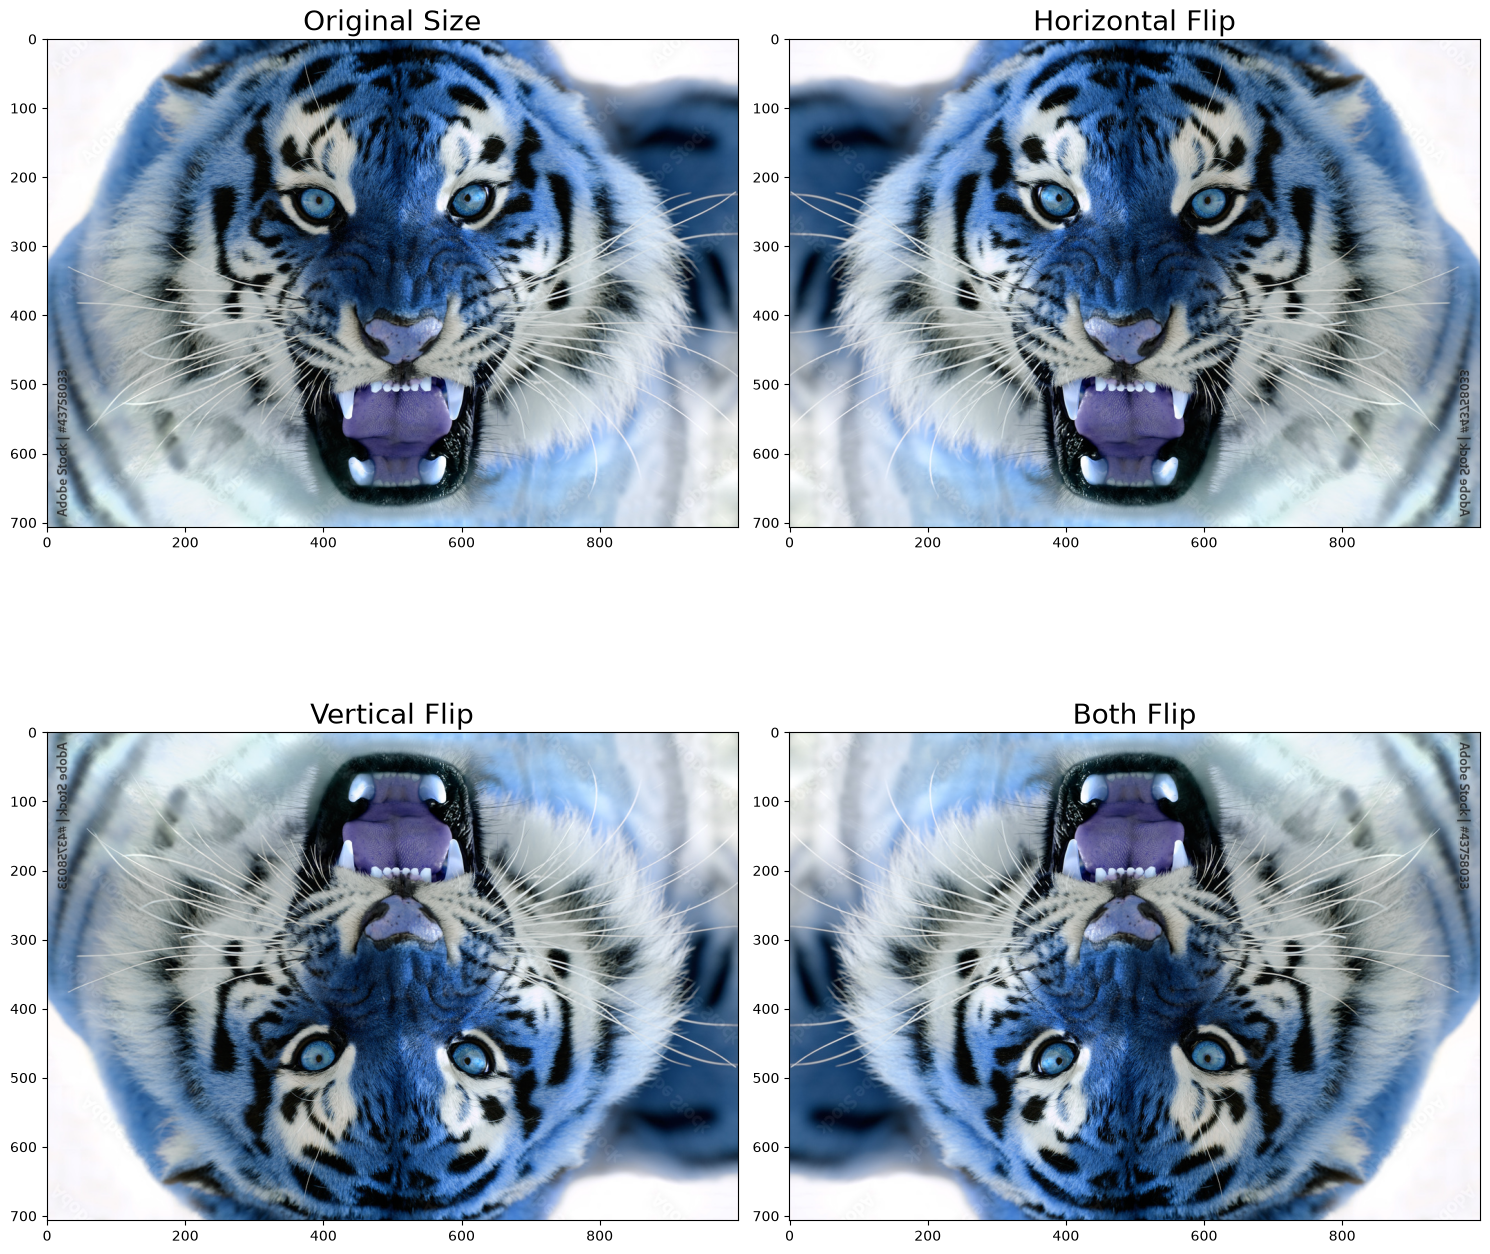

In [19]:
opencv_tools.show_img_by_matplotlib_2x2(
    "Original Size", img,
    "Horizontal Flip", horizontal_flip,
    "Vertical Flip", vertical_flip,
    "Both Flip", both_flip
    )

### Warp Affine Image

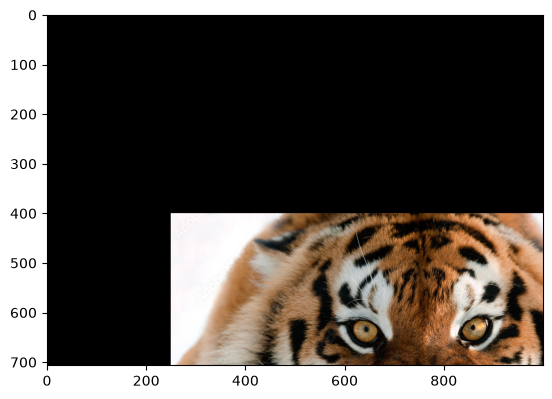

In [5]:
tx, ty = 250, 400
M = np.float32([[1, 0, tx], [0, 1, ty]])
affine_img = cv2.warpAffine(src=img, M=M, dsize=(img.shape[1], img.shape[0]))
plt.imshow(affine_img, cmap='gray')


### Rotation Matrix Image

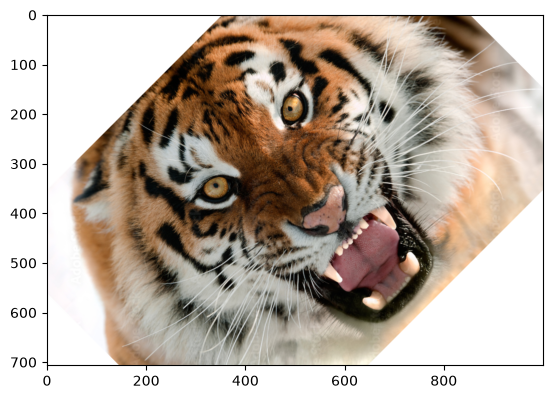

In [7]:
h, w, c = img.shape
center = (w // 2, h //2)
rotation_matrix = cv2.getRotationMatrix2D(center=center, angle=45, scale=1.0)
affine_img = cv2.warpAffine(src=img, M=rotation_matrix, dsize=(w, h), borderValue=(255, 255, 255))
plt.imshow(affine_img, cmap='gray')

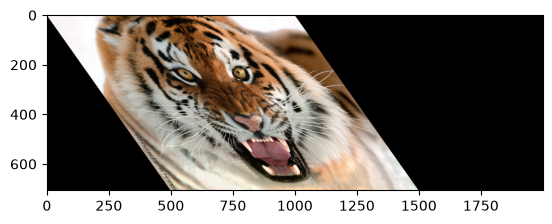

In [9]:
original_point = np.float32([[0, 0], [w, 0], [0, h]])
moved_point = np.float32([(0, 0), (w, 0), (w//2, h)])
M = cv2.getAffineTransform(src=original_point, dst=moved_point)
affine_img = cv2.warpAffine(src=img, M=M, dsize=(2*w, h))
plt.imshow(affine_img, cmap='gray')